# Baseline Regression Models for Temperature Predicition based on Features Extracted from Spectrograms

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.svm import SVR

from src.data.data_manager import create_data_loaders, create_file_based_splits
from src.utils.config_manager import load_config
from src.utils.baselines.feature_extraction import extract_features_from_indices

In [2]:
plt.rcParams['figure.figsize'] = (12, 6)

config = load_config()
mode = config['model'].get('type', 'regression')

print(f"Configuration:")
print(f"  - Sample rate: {config['data']['sample_rate']}")
print(f"  - Slice length: {config['data']['slice_length']}s")
print(f"  - Test split: {config['data']['test_split']}")
print(f"  - Val split: {config['data']['val_split']}")

train_loader, val_loader, test_loader, dataset = create_data_loaders(config)

print(f"\nSet sizes:")
print(f"  - Train: {len(train_loader.dataset)} samples")
print(f"  - Val: {len(val_loader.dataset)} samples")
print(f"  - Test: {len(test_loader.dataset)} samples")

Configuration:
  - Sample rate: 48000
  - Slice length: 0.1s
  - Test split: 0.2
  - Val split: 0.2
Total samples: 1975
Total unique audio files: 333
Split results:
  Train files: 212 -> 1261 slices
  Val files: 54 -> 329 slices
  Test files: 67 -> 385 slices

Set sizes:
  - Train: 1261 samples
  - Val: 329 samples
  - Test: 385 samples


Label shapes:
  - Train: (1261,)
  - Val: (329,)
  - Test: (385,)

Statistics (train):
  - Min: 29.00°C
  - Max: 45.00°C
  - Mean: 37.22°C
  - Median: 37.50°C
  - Std: 4.57°C


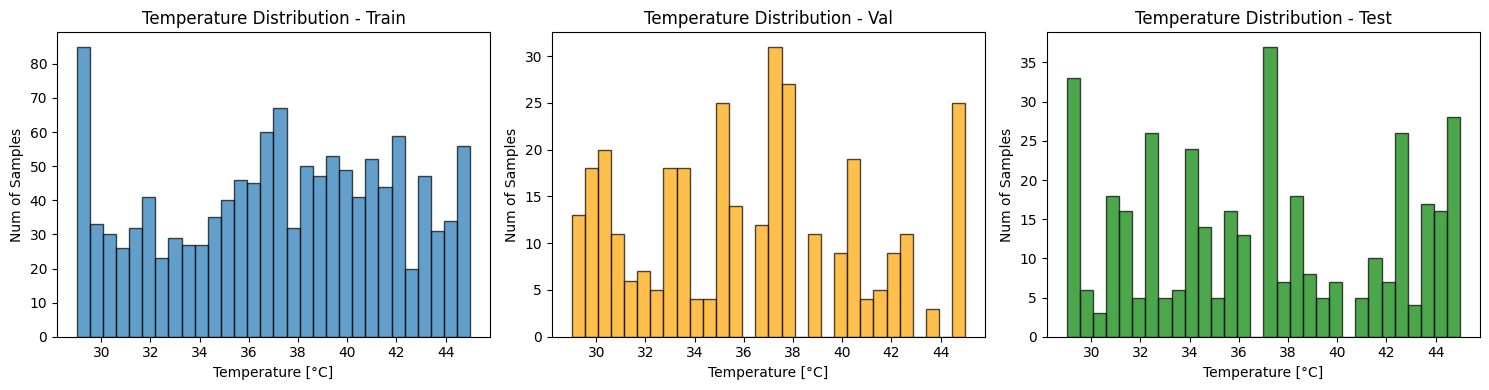

In [3]:
def extract_labels(data_loader):
    labels = []
    for _, label in data_loader:
        if isinstance(label, torch.Tensor):
            labels.extend(label.cpu().numpy())
        else:
            labels.extend(label)
    return np.array(labels)

y_train = extract_labels(train_loader)
y_val = extract_labels(val_loader)
y_test = extract_labels(test_loader)

print("Label shapes:")
print(f"  - Train: {y_train.shape}")
print(f"  - Val: {y_val.shape}")
print(f"  - Test: {y_test.shape}")

y_train = y_train.flatten()
y_val = y_val.flatten()
y_test = y_test.flatten()
print(f"\nStatistics (train):")
print(f"  - Min: {y_train.min():.2f}°C")
print(f"  - Max: {y_train.max():.2f}°C")
print(f"  - Mean: {y_train.mean():.2f}°C")
print(f"  - Median: {np.median(y_train):.2f}°C")
print(f"  - Std: {y_train.std():.2f}°C")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(y_train, bins=30, alpha=0.7, edgecolor='black')
axes[0].set_title('Temperature Distribution - Train')
axes[0].set_xlabel('Temperature [°C]')
axes[0].set_ylabel('Num of Samples')
axes[1].hist(y_val, bins=30, alpha=0.7, edgecolor='black', color='orange')
axes[1].set_title('Temperature Distribution - Val')
axes[1].set_xlabel('Temperature [°C]')
axes[1].set_ylabel('Num of Samples')
axes[2].hist(y_test, bins=30, alpha=0.7, edgecolor='black', color='green')
axes[2].set_title('Temperature Distribution - Test')
axes[2].set_xlabel('Temperature [°C]')
axes[2].set_ylabel('Num of Samples')

plt.tight_layout()
plt.savefig('../../results/baselines/data_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
train_indices, val_indices, test_indices = create_file_based_splits(
    dataset,
    test_split=config['data']['test_split'],
    val_split=config['data']['val_split'],
    random_seed=config['data']['random_seed']
)

train_val_indices = np.concatenate([train_indices, val_indices]) # we'll do GridSearchCV, val set not needed and will be used in train

print(f"\nNew size of train: {train_val_indices.size}")

X_train, y_train, groups_train = extract_features_from_indices(dataset, train_val_indices)
X_test, y_test, groups_test = extract_features_from_indices(dataset, test_indices)

X_train = np.nan_to_num(X_train, nan=0.0, posinf=0.0, neginf=0.0)
X_test = np.nan_to_num(X_test, nan=0.0, posinf=0.0, neginf=0.0)

print("\nFEATURE EXTRACTION")
print(f"Shape of features:")
print(f"  - X_train: {X_train.shape}")
print(f"  - X_test: {X_test.shape}")
print(f"  - Number of features: {X_train.shape[1]}")

Total unique audio files: 333
Split results:
  Train files: 212 -> 149 slices
  Val files: 54 -> 329 slices
  Test files: 67 -> 385 slices

New size of train: 478

FEATURE EXTRACTION
Shape of features:
  - X_train: (478, 51)
  - X_test: (385, 51)
  - Number of features: 51


In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
def convert_groups_to_numeric(groups):
    unique_groups = np.unique(groups)
    group_mapping = {g: i for i, g in enumerate(unique_groups)}
    return np.array([group_mapping[g] for g in groups])

## Ridge and ElasticNet Regression

In [9]:
def train_ridge_regression(X_train, y_train, groups_train):
    alpha_candidates = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]

    ridge_params = {'alpha': alpha_candidates}

    if isinstance(groups_train[0], (str, np.str_)):
            groups_numeric = convert_groups_to_numeric(groups_train)
    else:
        groups_numeric = groups_train

    cv = GroupKFold(n_splits=5)
    ridge_cv = GridSearchCV(
        Ridge(),
        ridge_params,
        cv=cv,
        scoring='r2',
        n_jobs=-1,
        verbose=1
    )
    ridge_cv.fit(X_train, y_train, groups=groups_numeric)

    return ridge_cv.best_estimator_, ridge_cv.best_params_, ridge_cv.best_score_

In [10]:
def train_elasticnet_regression(X_train, y_train, groups_train):
    alpha_candidates = [0.0001, 0.001, 0.01, 0.1, 1.0]
    l1_ratio_candidates = [0.1, 0.3, 0.5, 0.7, 0.9]

    elasticnet_params = {
        'alpha': alpha_candidates,
        'l1_ratio': l1_ratio_candidates
    }

    if isinstance(groups_train[0], (str, np.str_)):
            groups_numeric = convert_groups_to_numeric(groups_train)
    else:
        groups_numeric = groups_train

    cv = GroupKFold(n_splits=5)
    elasticnet_cv = GridSearchCV(
        ElasticNet(max_iter=10000, random_state=42),
        elasticnet_params,
        cv=cv,
        scoring='r2',
        n_jobs=-1,
        verbose=1
    )
    elasticnet_cv.fit(X_train, y_train, groups=groups_numeric)

    return elasticnet_cv.best_estimator_, elasticnet_cv.best_params_, elasticnet_cv.best_score_

In [11]:
def evaluate_models(y_true, y_pred_ridge, y_pred_elasticnet):
    ridge_r2 = r2_score(y_true, y_pred_ridge)
    ridge_rmse = np.sqrt(mean_squared_error(y_true, y_pred_ridge))
    ridge_mae = mean_absolute_error(y_true, y_pred_ridge)

    elasticnet_r2 = r2_score(y_true, y_pred_elasticnet)
    elasticnet_rmse = np.sqrt(mean_squared_error(y_true, y_pred_elasticnet))
    elasticnet_mae = mean_absolute_error(y_true, y_pred_elasticnet)

    results_df = pd.DataFrame({
        'Model': ['Ridge', 'ElasticNet'],
        'R2': [ridge_r2, elasticnet_r2],
        'RMSE': [ridge_rmse, elasticnet_rmse],
        'MAE': [ridge_mae, elasticnet_mae]
    })

    return results_df

def plot_predictions(y_test, y_pred_ridge_test, y_pred_elasticnet_test, figsize=(14, 10)):
    ridge_test_r2 = r2_score(y_test, y_pred_ridge_test)
    ridge_test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge_test))
    ridge_test_mae = mean_absolute_error(y_test, y_pred_ridge_test)

    elasticnet_test_r2 = r2_score(y_test, y_pred_elasticnet_test)
    elasticnet_test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_elasticnet_test))
    elasticnet_test_mae = mean_absolute_error(y_test, y_pred_elasticnet_test)

    fig, axes = plt.subplots(2, 2, figsize=figsize)

    # Ridge predictions
    axes[0, 0].scatter(y_test, y_pred_ridge_test, alpha=0.6, edgecolors='k', color='blue')
    axes[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[0, 0].set_xlabel('True Temperature [°C]')
    axes[0, 0].set_ylabel('Predicted Temperature [°C]')
    axes[0, 0].set_title(f'Ridge - Test Set\nR² = {ridge_test_r2:.4f}, RMSE = {ridge_test_rmse:.4f}, MAE = {ridge_test_mae:.4f}')
    axes[0, 0].grid(True, alpha=0.3)

    # Ridge residuals
    residuals_ridge_test = y_test - y_pred_ridge_test
    axes[0, 1].hist(residuals_ridge_test, bins=30, edgecolor='black', alpha=0.7, color='blue')
    axes[0, 1].axvline(residuals_ridge_test.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {residuals_ridge_test.mean():.4f}')
    axes[0, 1].set_xlabel('Residuals [°C]')
    axes[0, 1].set_ylabel('Frequency')
    axes[0, 1].set_title(f'Ridge - Test Residuals\nStd = {residuals_ridge_test.std():.4f}')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3, axis='y')

    # ElasticNet predictions
    axes[1, 0].scatter(y_test, y_pred_elasticnet_test, alpha=0.6, edgecolors='k', color='green')
    axes[1, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[1, 0].set_xlabel('True Temperature [°C]')
    axes[1, 0].set_ylabel('Predicted Temperature [°C]')
    axes[1, 0].set_title(f'ElasticNet - Test Set\nR² = {elasticnet_test_r2:.4f}, RMSE = {elasticnet_test_rmse:.4f}, MAE = {elasticnet_test_mae:.4f}')
    axes[1, 0].grid(True, alpha=0.3)

    # ElasticNet residuals
    residuals_elasticnet_test = y_test - y_pred_elasticnet_test
    axes[1, 1].hist(residuals_elasticnet_test, bins=30, edgecolor='black', alpha=0.7, color='green')
    axes[1, 1].axvline(residuals_elasticnet_test.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {residuals_elasticnet_test.mean():.4f}')
    axes[1, 1].set_xlabel('Residuals [°C]')
    axes[1, 1].set_ylabel('Frequency')
    axes[1, 1].set_title(f'ElasticNet - Test Residuals\nStd = {residuals_elasticnet_test.std():.4f}')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    return fig

Fitting 5 folds for each of 7 candidates, totalling 35 fits
Ridge - Best params: {'alpha': 1.0}, CV R²: 0.1751
Fitting 5 folds for each of 25 candidates, totalling 125 fits


C:\Users\Ania\PycharmProjects\vibro-ml-v1\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.668e+02, tolerance: 1.205e+00
  model = cd_fast.enet_coordinate_descent(


ElasticNet - Best params: {'alpha': 0.001, 'l1_ratio': 0.1}, CV R²: 0.1721
        Model        R2      RMSE       MAE
0       Ridge  0.264717  4.254893  3.385703
1  ElasticNet  0.266529  4.249647  3.380585


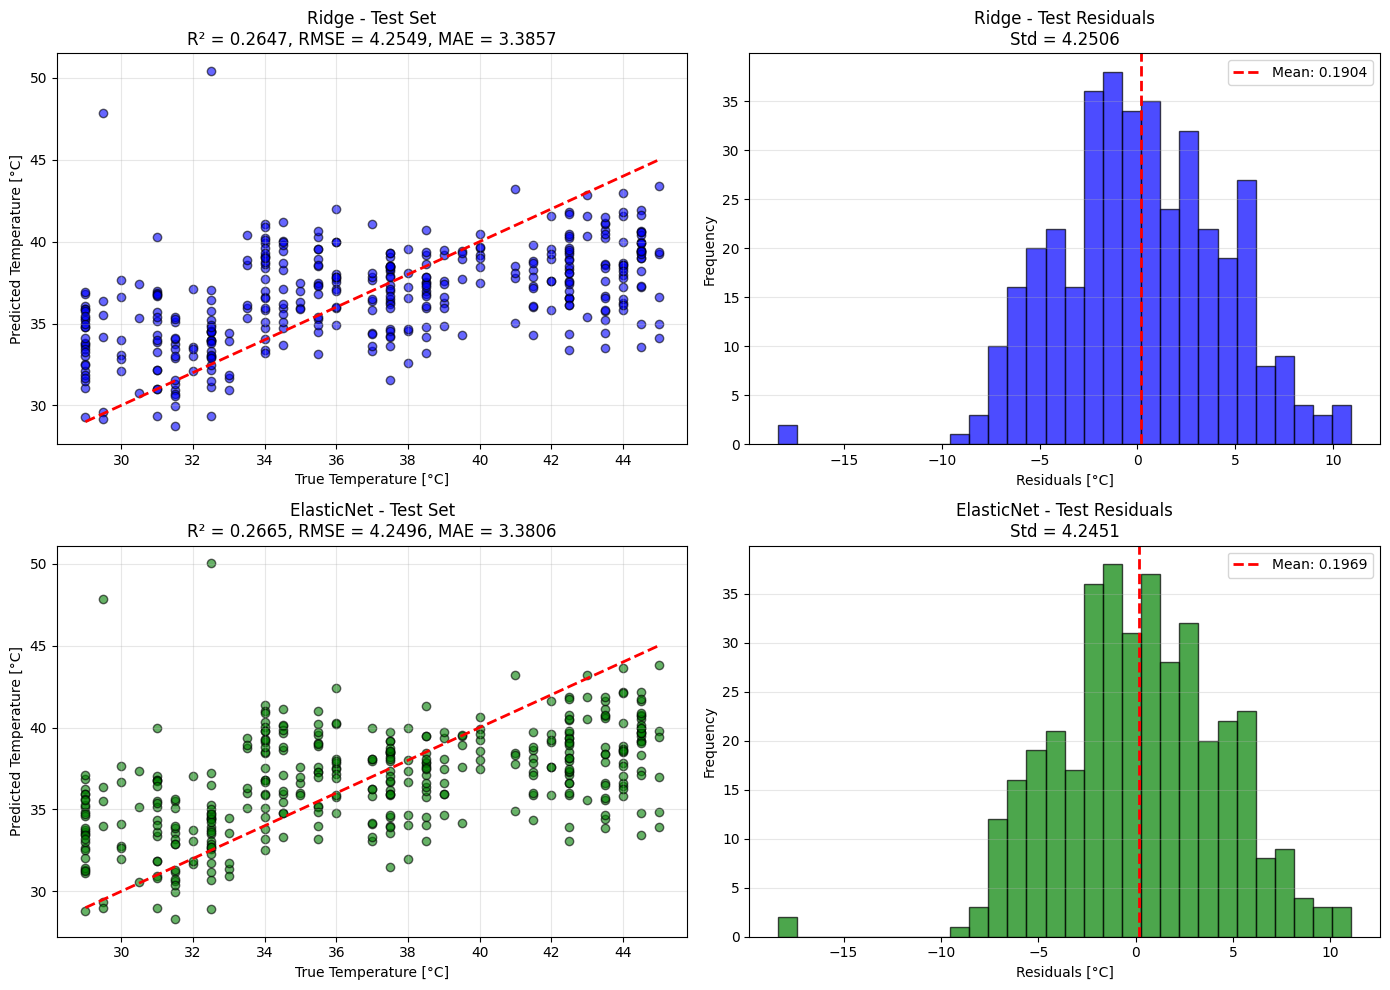

In [12]:
ridge_model, ridge_params, ridge_cv_score = train_ridge_regression(
    X_train_scaled, y_train, groups_train=groups_train
)
print(f"Ridge - Best params: {ridge_params}, CV R²: {ridge_cv_score:.4f}")

elasticnet_model, elasticnet_params, elasticnet_cv_score = train_elasticnet_regression(
    X_train_scaled, y_train, groups_train=groups_train
)
print(f"ElasticNet - Best params: {elasticnet_params}, CV R²: {elasticnet_cv_score:.4f}")

y_pred_ridge_test = ridge_model.predict(X_test_scaled)
y_pred_elasticnet_test = elasticnet_model.predict(X_test_scaled)

results_df = evaluate_models(y_test, y_pred_ridge_test, y_pred_elasticnet_test)
print(results_df)
fig = plot_predictions(y_test, y_pred_ridge_test, y_pred_elasticnet_test)
plt.show()

## Support Vector Regression (SVR)

In [ ]:
def train_svr(X_train, y_train, groups_train):
    kernel_candidates = ['linear', 'rbf']
    C_candidates = [0.1, 1.0, 10.0, 100.0, 1000.0]
    gamma_candidates = ['scale', 'auto']

    svr_params = {
        'kernel': kernel_candidates,
        'C': C_candidates,
        'gamma': gamma_candidates
    }

    if isinstance(groups_train[0], (str, np.str_)):
            groups_numeric = convert_groups_to_numeric(groups_train)
    else:
        groups_numeric = groups_train

    cv = GroupKFold(n_splits=5)
    svr_cv = GridSearchCV(
        SVR(),
        svr_params,
        cv=cv,
        scoring='r2',
        n_jobs=-1,
        verbose=1
    )
    svr_cv.fit(X_train, y_train, groups=groups_numeric)

    return svr_cv.best_estimator_, svr_cv.best_params_, svr_cv.best_score_

In [ ]:
## TODO: finish